# EDAB6808 Assignment 3 — Bayesian Networks and Probabilistic Inference


**Objective:** Build, compare and evaluate two Bayesian networks for heart-disease prediction:

1. an **expert/domain-informed DAG**, and  
2. a **data-driven DAG** learned with `bnlearn`.

The purpose of this assignment is to build, compare, and evaluate two Bayesian networks for
heart-disease prediction: one network specified using domain-informed reasoning and one
network learned from data using bnlearn. The analysis follows the complete Bayesian-network
workflow required by the assignment rubric: data preparation, structure learning, parameter
learning, probabilistic inference, and held-out model evaluation.


written by:Reatile Seekoei and Mamello Malape

## 1. Environment, imports and reproducibility

In [ ]:
# Colab setup: install bnlearn only. Avoid forced upgrades of scipy/numpy,
# because they can create dependency conflicts in Colab.
!pip -q install bnlearn

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 60.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 189.9/189.9 kB 14.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 145.6/145.6 kB 11.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 83.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 162.6/162.6 kB 13.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.6/84.6 kB 7.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 8.0 MB/s eta 0:00:00


In [ ]:
import os
import sys
import pickle
import warnings
from itertools import product

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
import bnlearn as bn

from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, balanced_accuracy_score,
    confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, precision_recall_curve
)
from pgmpy.inference import VariableElimination

warnings.filterwarnings('ignore')

RANDOM_STATE = 42
TARGET = 'heartdisease_bin'
DATA_PATH = '/content/diabetes.csv'

np.random.seed(RANDOM_STATE)

print('Python:', sys.version.split()[0])
print('pandas:', pd.__version__)
print('numpy:', np.__version__)
print('bnlearn:', getattr(bn, '__version__', 'version not exposed'))

/usr/local/lib/python3.13/dist-packages/pgmpy/estimators/__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (


Python: 3.13.15
pandas: 2.2.3
numpy: 2.1.3
bnlearn: 0.15.0


## 2. Data ingestion and schema validation

The supplied CSV has missing observations in `ca` and `thal` are encoded as the literal string `?`. Those should be corrected **before** EDA or modelling.

In [ ]:
# Treat '?' as missing on import and standardise the column naming immediately.
df = pd.read_csv("/content/diabetes.csv")

expected_cols = [
    'age', 'gender', 'cp', 'trestbps', 'chol', 'fbs', 'restecg',
    'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'heartdisease'
]

missing_cols = [c for c in expected_cols if c not in df.columns]
extra_cols = [c for c in df.columns if c not in expected_cols]

assert not missing_cols, f'Missing required columns: {missing_cols}'

# Convert the two columns that contained '?' strings to numeric.
df['ca'] = pd.to_numeric(df['ca'], errors='coerce')
df['thal'] = pd.to_numeric(df['thal'], errors='coerce')

print('Shape:', df.shape)
print('Extra columns:', extra_cols)
print('Duplicate rows:', int(df.duplicated().sum()))
print('\nData types:')
print(df.dtypes)
print('\nMissing values after converting ? to NaN:')
print(df.isna().sum()[df.isna().sum() > 0])

display(df.head())

Shape: (303, 14)
Extra columns: []
Duplicate rows: 0

Data types:
age               int64
gender            int64
cp                int64
trestbps          int64
chol              int64
fbs               int64
restecg           int64
thalach           int64
exang             int64
oldpeak         float64
slope             int64
ca              float64
thal            float64
heartdisease      int64
dtype: object

Missing values after converting ? to NaN:
ca      4
thal    2
dtype: int64


,age,gender,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,heartdisease
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,2
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


### 2.1 Validate coded categorical states

In [ ]:
allowed_states = {
    'gender': {0, 1},
    'cp': {1, 2, 3, 4},
    'fbs': {0, 1},
    'restecg': {0, 1, 2},
    'exang': {0, 1},
    'slope': {1, 2, 3},
    'ca': {0, 1, 2, 3},
    'thal': {3, 6, 7},
    'heartdisease': {0, 1, 2, 3, 4},
}

validation_rows = []
for col, allowed in allowed_states.items():
    observed = set(pd.Series(df[col].dropna().unique()).astype(int).tolist())
    unexpected = observed - allowed
    validation_rows.append({
        'Variable': col,
        'Observed states': sorted(observed),
        'Unexpected states': sorted(unexpected),
        'Valid': len(unexpected) == 0
    })

validation_table = pd.DataFrame(validation_rows)
display(validation_table)
assert validation_table['Valid'].all(), 'Unexpected coded states were found.'

,Variable,Observed states,Unexpected states,Valid
0,gender,"[0, 1]",[],True
1,cp,"[1, 2, 3, 4]",[],True
2,fbs,"[0, 1]",[],True
3,restecg,"[0, 1, 2]",[],True
4,exang,"[0, 1]",[],True
5,slope,"[1, 2, 3]",[],True
6,ca,"[0, 1, 2, 3]",[],True
7,thal,"[3, 6, 7]",[],True
8,heartdisease,"[0, 1, 2, 3, 4]",[],True


## 3. Exploratory analysis and target definition

The original `heartdisease` target ranges from 0 to 4. For the assignment's classification/inference task we define:

- `heartdisease_bin = 0`: no heart disease; and
- `heartdisease_bin = 1`: any recorded presence of heart disease (original classes 1–4).

This avoids modelling very sparse severity classes while preserving the clinically relevant presence/absence decision.

,Class,Count,Percent
0,No disease (0),164,54.1
1,Disease present (1),139,45.9


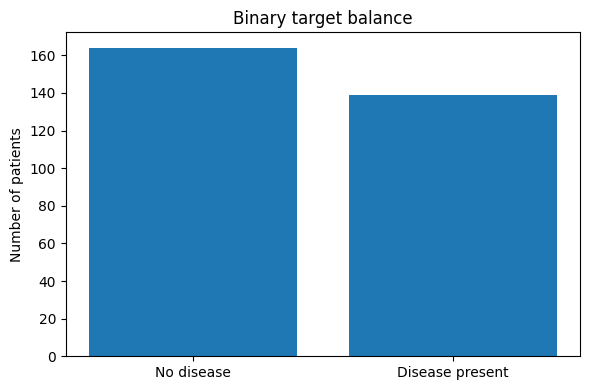

In [ ]:
df[TARGET] = (df['heartdisease'] > 0).astype(int)

class_counts = df[TARGET].value_counts().sort_index()
class_pct = (df[TARGET].value_counts(normalize=True).sort_index() * 100).round(1)

balance_table = pd.DataFrame({
    'Class': ['No disease (0)', 'Disease present (1)'],
    'Count': [class_counts.get(0, 0), class_counts.get(1, 0)],
    'Percent': [class_pct.get(0, 0), class_pct.get(1, 0)]
})
display(balance_table)

plt.figure(figsize=(6, 4))
plt.bar(['No disease', 'Disease present'], balance_table['Count'])
plt.ylabel('Number of patients')
plt.title('Binary target balance')
plt.tight_layout()
plt.show()

### 3.1 Numeric EDA

Pearson correlation is shown only for genuinely numeric/ordered measurements. Numerically coded nominal variables such as `cp`, `restecg` and `thal` are not treated as continuous measurements in this heatmap.

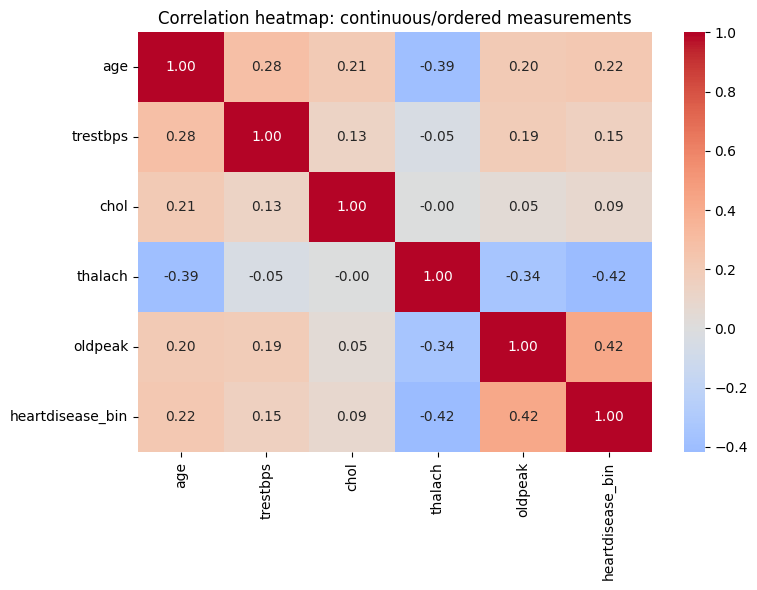

In [ ]:
numeric_eda_cols = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak', TARGET]
corr = df[numeric_eda_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation heatmap: continuous/ordered measurements')
plt.tight_layout()
plt.show()

### 3.2 Categorical outcome-rate summaries

In [ ]:
categorical_eda_cols = ['gender', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']

outcome_summaries = []
for col in categorical_eda_cols:
    temp = (
        df.groupby(col, dropna=False)[TARGET]
          .agg(['count', 'mean'])
          .reset_index()
          .rename(columns={'mean': 'P(disease=1)'})
    )
    temp.insert(0, 'Variable', col)
    outcome_summaries.append(temp)

categorical_outcome_table = pd.concat(outcome_summaries, ignore_index=True)
display(categorical_outcome_table)

,Variable,gender,count,P(disease=1),cp,fbs,restecg,exang,slope,ca,thal
0,gender,0.0,97,0.257732,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,gender,1.0,206,0.553398,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,cp,NaN,23,0.304348,1.0,NaN,NaN,NaN,NaN,NaN,NaN
3,cp,NaN,50,0.180000,2.0,NaN,NaN,NaN,NaN,NaN,NaN
4,cp,NaN,86,0.209302,3.0,NaN,NaN,NaN,NaN,NaN,NaN
5,cp,NaN,144,0.729167,4.0,NaN,NaN,NaN,NaN,NaN,NaN
6,fbs,NaN,258,0.453488,NaN,0.0,NaN,NaN,NaN,NaN,NaN
7,fbs,NaN,45,0.488889,NaN,1.0,NaN,NaN,NaN,NaN,NaN
8,restecg,NaN,151,0.370861,NaN,NaN,0.0,NaN,NaN,NaN,NaN
9,restecg,NaN,4,0.750000,NaN,NaN,1.0,NaN,NaN,NaN,NaN


## 4. Train/test split — before imputation and discretisation

The held-out test set must not influence model structure, parameters, imputation values or discretisation boundaries. We therefore split first, using stratification to preserve the binary target balance.

In [ ]:
train_df, test_df = train_test_split(
    df,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=df[TARGET]
)

train_df = train_df.copy()
test_df = test_df.copy()

split_summary = pd.DataFrame({
    'Dataset': ['Training', 'Test'],
    'Rows': [len(train_df), len(test_df)],
    'Disease prevalence': [train_df[TARGET].mean(), test_df[TARGET].mean()]
})
display(split_summary)

,Dataset,Rows,Disease prevalence
0,Training,242,0.458678
1,Test,61,0.459016


## 5. Missing-value treatment — learned on training data only

Only `ca` and `thal` contain missing values. Because both are discrete clinical variables and missingness is very limited, we use **training-set mode imputation**. The imputation values are then applied unchanged to the test set.

In [ ]:
missing_cols_to_impute = ['ca', 'thal']
imputation_values = {}

for col in missing_cols_to_impute:
    mode_value = train_df[col].mode(dropna=True).iloc[0]
    imputation_values[col] = int(mode_value)
    train_df[col] = train_df[col].fillna(mode_value).astype(int)
    test_df[col] = test_df[col].fillna(mode_value).astype(int)

print('Training-derived imputation values:', imputation_values)
print('Remaining train missing values:', int(train_df[missing_cols_to_impute].isna().sum().sum()))
print('Remaining test missing values :', int(test_df[missing_cols_to_impute].isna().sum().sum()))

Training-derived imputation values: {'ca': 0, 'thal': 3}
Remaining train missing values: 0
Remaining test missing values : 0


## 6. Discretisation — boundaries learned on training data only

The continuous variables are converted into three quantile-based categories (`Low`, `Medium`, `High`) to support discrete CPT/CPD estimation. The quantile boundaries are learned from the training sample only. The outer edges are extended to ±∞ when applied so that valid future/test observations are not discarded merely for falling slightly outside the training minimum or maximum.

In [ ]:
continuous_cols = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
category_names = {
    'age': 'age_cat',
    'trestbps': 'trestbp_cat',
    'chol': 'chol_cat',
    'thalach': 'thalach_cat',
    'oldpeak': 'oldpeak_cat'
}
base_labels = ['Low', 'Medium', 'High']
bin_edges = {}

for col in continuous_cols:
    # Learn quantile cut points from TRAIN only.
    _, raw_edges = pd.qcut(
        train_df[col],
        q=3,
        retbins=True,
        duplicates='drop'
    )

    safe_edges = np.asarray(raw_edges, dtype=float).copy()
    safe_edges[0] = -np.inf
    safe_edges[-1] = np.inf
    labels = base_labels[:len(safe_edges) - 1]

    train_df[category_names[col]] = pd.cut(
        train_df[col], bins=safe_edges, labels=labels, include_lowest=True
    )
    test_df[category_names[col]] = pd.cut(
        test_df[col], bins=safe_edges, labels=labels, include_lowest=True
    )
    bin_edges[col] = safe_edges

# Document the binning rules.
bin_rows = []
for raw_col, edges in bin_edges.items():
    labels = base_labels[:len(edges)-1]
    for i, label in enumerate(labels):
        lower = '-∞' if np.isneginf(edges[i]) else round(float(edges[i]), 3)
        upper = '∞' if np.isposinf(edges[i+1]) else round(float(edges[i+1]), 3)
        bin_rows.append({
            'Raw variable': raw_col,
            'BN variable': category_names[raw_col],
            'State': label,
            'Interval': f'({lower}, {upper}]'
        })

bin_definition_table = pd.DataFrame(bin_rows)
display(bin_definition_table)

,Raw variable,BN variable,State,Interval
0,age,age_cat,Low,"(-∞, 51.0]"
1,age,age_cat,Medium,"(51.0, 59.0]"
2,age,age_cat,High,"(59.0, ∞]"
3,trestbps,trestbp_cat,Low,"(-∞, 120.0]"
4,trestbps,trestbp_cat,Medium,"(120.0, 139.333]"
5,trestbps,trestbp_cat,High,"(139.333, ∞]"
6,chol,chol_cat,Low,"(-∞, 226.0]"
7,chol,chol_cat,Medium,"(226.0, 266.667]"
8,chol,chol_cat,High,"(266.667, ∞]"
9,thalach,thalach_cat,Low,"(-∞, 143.0]"


## 7. Final modelling dataset

The original continuous columns and original 5-level target are removed from the BN modelling frame. The categorical states are aligned between training and test data.

In [ ]:
drop_from_bn = continuous_cols + ['heartdisease']
train_bn = train_df.drop(columns=drop_from_bn).copy()
test_bn = test_df.drop(columns=drop_from_bn).copy()

# Convert training variables to categories and force test data to use exactly
# the same state space.
for col in train_bn.columns:
    train_bn[col] = train_bn[col].astype('category')
    test_bn[col] = pd.Categorical(
        test_bn[col],
        categories=train_bn[col].cat.categories
    )

assert not train_bn.isna().any().any(), 'Training BN data still contains missing values.'
assert not test_bn.isna().any().any(), 'Test BN data contains states outside the training state space.'
assert TARGET in train_bn.columns and TARGET in test_bn.columns

schema_rows = []
for col in train_bn.columns:
    schema_rows.append({
        'Variable': col,
        'Number of states': train_bn[col].nunique(),
        'States': list(train_bn[col].cat.categories),
        'Role': 'Target' if col == TARGET else 'Predictor / evidence'
    })

modelling_schema = pd.DataFrame(schema_rows)
print('Training BN shape:', train_bn.shape)
print('Test BN shape    :', test_bn.shape)
display(modelling_schema)

Training BN shape: (242, 14)
Test BN shape    : (61, 14)


,Variable,Number of states,States,Role
0,gender,2,"[0, 1]",Predictor / evidence
1,cp,4,"[1, 2, 3, 4]",Predictor / evidence
2,fbs,2,"[0, 1]",Predictor / evidence
3,restecg,3,"[0, 1, 2]",Predictor / evidence
4,exang,2,"[0, 1]",Predictor / evidence
5,slope,3,"[1, 2, 3]",Predictor / evidence
6,ca,4,"[0, 1, 2, 3]",Predictor / evidence
7,thal,3,"[3, 6, 7]",Predictor / evidence
8,heartdisease_bin,2,"[0, 1]",Target
9,age_cat,3,"[Low, Medium, High]",Predictor / evidence


### Feature-selection decision

No additional predictor is removed before structure learning. The dataset is already a small, established Cleveland subset, and Bayesian-network structure learning itself determines which conditional dependencies are retained. The expert DAG also uses every modelling variable, but organises them into clinically interpretable diagnostic pathways rather than connecting every variable directly to the target.

## 8. Expert/domain-informed DAG

### Design rationale

The original notebook connected almost every predictor directly to `heartdisease_bin`. That made the target CPT extremely sparse relative to the training sample. The revised expert DAG uses a **diagnostic-network structure**:

- demographic/physiological risk information feeds the disease node;
- the disease node probabilistically influences symptoms and diagnostic findings;
- exercise-related observations are organised into an exercise-test pathway.

This keeps all variables while reducing the number of direct parents of the target. The directions represent a defensible BN factorisation and diagnostic reasoning pathway, not proof of causality.

| Edge | Domain justification |
|---|---|
| age_cat → trestbp_cat | Resting blood pressure tends to vary with age. |
| age_cat → heartdisease_bin | Age is an established cardiovascular risk-profile variable. |
| sex → heartdisease_bin | Cardiovascular risk profiles differ by sex. |
| trestbp_cat → heartdisease_bin | Elevated resting blood pressure is associated with cardiovascular burden. |
| chol_cat → heartdisease_bin | Serum cholesterol is relevant to atherosclerotic risk. |
| heartdisease_bin → cp | Chest-pain type is treated as an observed manifestation conditional on disease status in the diagnostic BN. |
| heartdisease_bin → restecg | ECG findings can differ according to underlying cardiac disease status. |
| heartdisease_bin → exang | Exercise-induced angina is an observed manifestation associated with coronary disease. |
| heartdisease_bin → ca | Fluoroscopy vessel findings are diagnostic evidence associated with disease status. |
| fbs → ca | Elevated glucose/diabetes-related risk can be associated with vascular burden. |
| heartdisease_bin → thal | The thallium-related diagnostic state is treated as evidence conditional on disease status. |
| heartdisease_bin → slope | Exercise ST-segment slope is diagnostic evidence associated with cardiac disease. |
| age_cat → thalach_cat | Maximum achievable heart rate typically varies with age. |
| heartdisease_bin → thalach_cat | Underlying cardiac disease can be associated with impaired exercise heart-rate response. |
| exang → oldpeak_cat | Exercise-induced angina and exercise-related ST depression are linked exercise-test findings. |
| slope → oldpeak_cat | ST-segment slope and ST depression are directly related exercise ECG features. |

[bnlearn]> Auto generate placeholders for the CPTs.
[bnlearn] >CPT for trestbp_cat:
+----------------+------------+------------+
| age_cat        | age_cat(0) | age_cat(1) |
+----------------+------------+------------+
| trestbp_cat(0) | 0.5        | 0.5        |
+----------------+------------+------------+
| trestbp_cat(1) | 0.5        | 0.5        |
+----------------+------------+------------+
[bnlearn] >CPT for heartdisease_bin:
+---------------------+-----+----------------+----------------+
| age_cat             | ... | age_cat(1)     | age_cat(1)     |
+---------------------+-----+----------------+----------------+
| gender              | ... | gender(1)      | gender(1)      |
+---------------------+-----+----------------+----------------+
| trestbp_cat         | ... | trestbp_cat(1) | trestbp_cat(1) |
+---------------------+-----+----------------+----------------+
| chol_cat            | ... | chol_cat(0)    | chol_cat(1)    |
+---------------------+-----+----------------+------

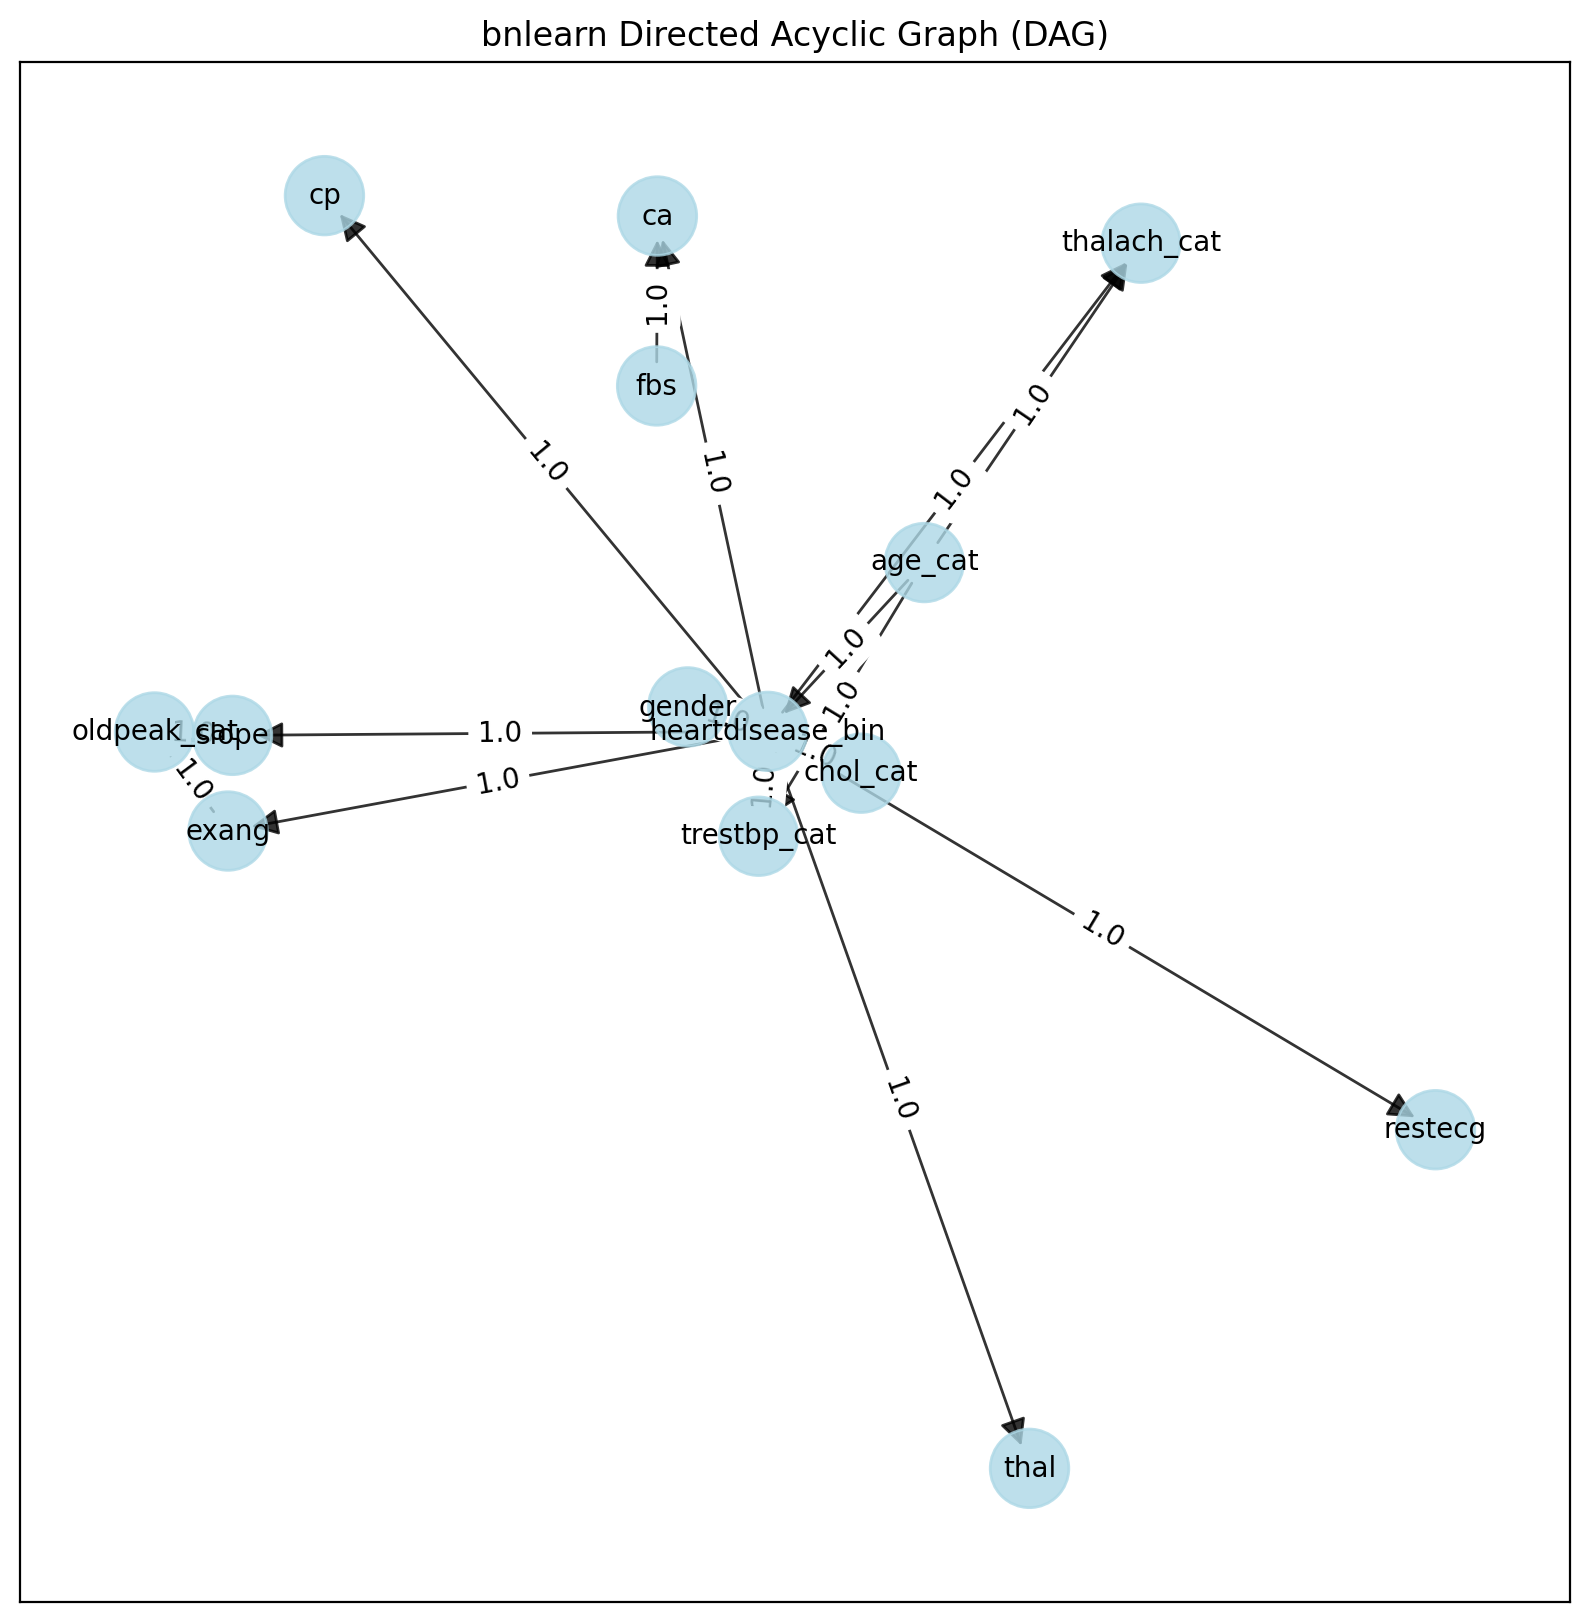

{'fig': <Figure size 2000x2000 with 1 Axes>,
 'ax': <Figure size 2000x2000 with 1 Axes>,
 'pos': {'age_cat': array([0.28625751, 0.15182009]),
  'trestbp_cat': array([ 0.0707184 , -0.19616909]),
  'heartdisease_bin': array([ 0.08283703, -0.06281406]),
  'gender': array([-0.02144897, -0.03171119]),
  'chol_cat': array([ 0.20410076, -0.11599102]),
  'cp': array([-0.49402946,  0.61842927]),
  'restecg': array([ 0.95129494, -0.56937445]),
  'exang': array([-0.61948712, -0.18955105]),
  'ca': array([-0.06090576,  0.59250042]),
  'fbs': array([-0.06190295,  0.37642337]),
  'thal': array([ 0.42317874, -1.        ]),
  'slope': array([-0.61366234, -0.06790398]),
  'thalach_cat': array([0.56814549, 0.55795225]),
  'oldpeak_cat': array([-0.71509625, -0.06361055])},
 'G': <networkx.classes.digraph.DiGraph at 0x7c8daae9f8c0>,
 'node_properties': {'age_cat': {'node_color': '#ADD8E6', 'node_size': 800},
  'trestbp_cat': {'node_color': '#ADD8E6', 'node_size': 800},
  'heartdisease_bin': {'node_color':

In [ ]:
expert_edges = [
    ('age_cat', 'trestbp_cat'),
    ('age_cat', TARGET),
    ('gender', TARGET),
    ('trestbp_cat', TARGET),
    ('chol_cat', TARGET),

    (TARGET, 'cp'),
    (TARGET, 'restecg'),
    (TARGET, 'exang'),
    (TARGET, 'ca'),
    ('fbs', 'ca'),
    (TARGET, 'thal'),
    (TARGET, 'slope'),

    ('age_cat', 'thalach_cat'),
    (TARGET, 'thalach_cat'),
    ('exang', 'oldpeak_cat'),
    ('slope', 'oldpeak_cat'),
]

DAG_expert = bn.make_DAG(expert_edges)

expert_graph = DAG_expert['model']
assert nx.is_directed_acyclic_graph(expert_graph), 'Expert graph is not acyclic.'
assert set(train_bn.columns).issubset(set(expert_graph.nodes())), 'Expert DAG is missing modelling variables.'

expert_target_parents = list(expert_graph.predecessors(TARGET))
parent_configurations = int(np.prod([train_bn[p].nunique() for p in expert_target_parents]))

print('Expert DAG edges:', len(expert_edges))
print('Direct parents of target:', expert_target_parents)
print('Possible target-parent configurations:', parent_configurations)
print('Training observations:', len(train_bn))

bn.plot(DAG_expert)

## 9. Data-driven DAG — Hill Climbing + BIC

Hill Climbing is used as the graph-search strategy, while BIC balances goodness-of-fit against model complexity. The structure is learned from **training data only**.

[bnlearn] >Warning: Computing DAG with 14 nodes can take a very long time!
[bnlearn] >Computing best DAG using [hc]
[bnlearn] >Set scoring type at [bic]
[bnlearn] >Compute structure scores for model comparison (higher is better).
Learned DAG edges: 11
[bnlearn] >Set node properties.
[bnlearn] >Set edge properties.
[bnlearn] >Plot based on Bayesian model


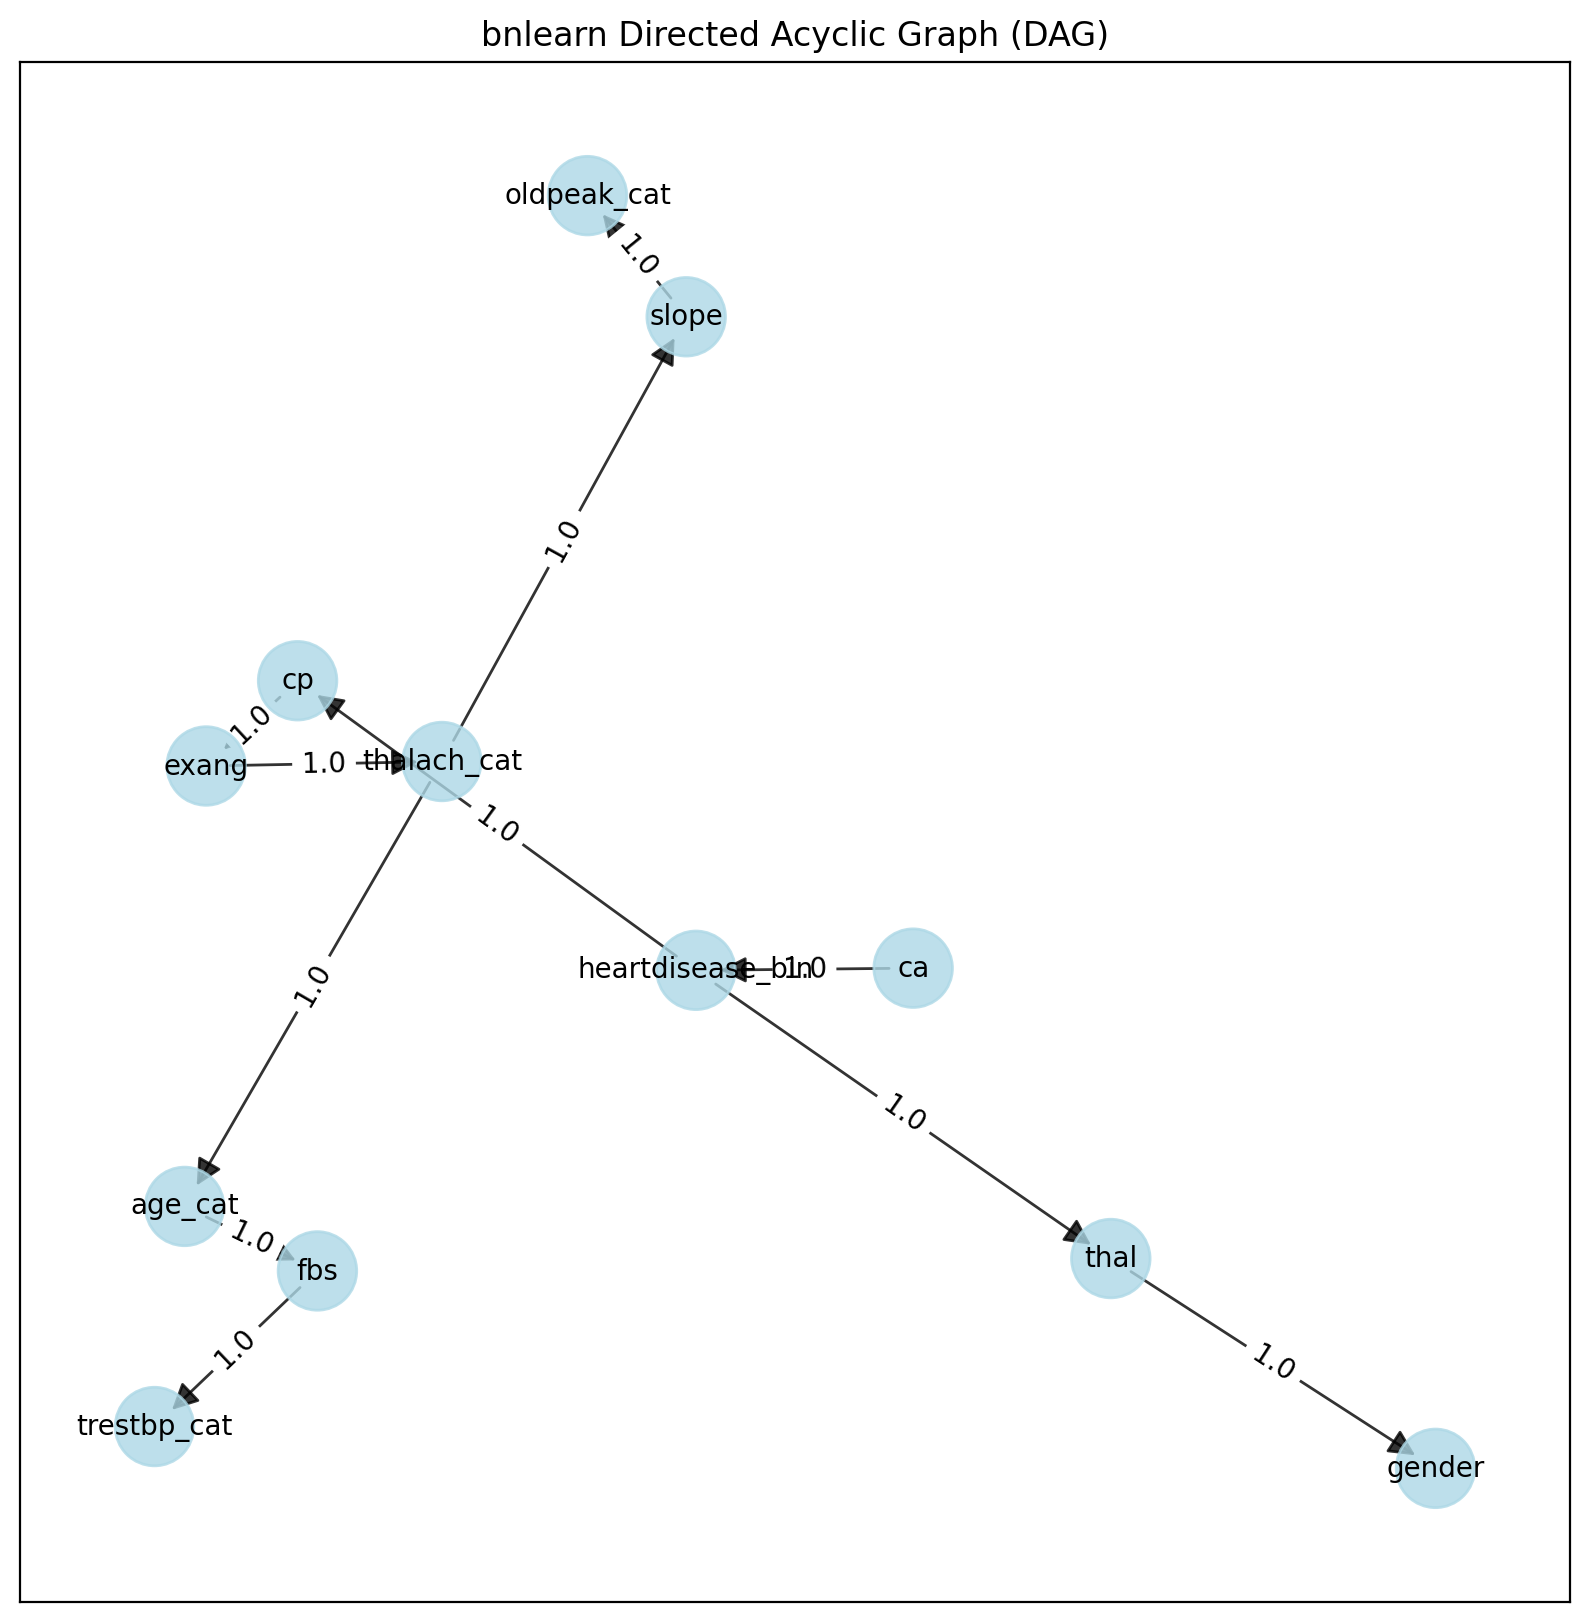

{'fig': <Figure size 2000x2000 with 1 Axes>,
 'ax': <Figure size 2000x2000 with 1 Axes>,
 'pos': {'gender': array([ 0.2698826 , -0.82125803]),
  'cp': array([-0.26730329,  0.3058307 ]),
  'fbs': array([-0.25793758, -0.53872523]),
  'restecg': array([0.69577272, 0.69132348]),
  'exang': array([-0.31046529,  0.18382789]),
  'slope': array([-0.0838515 ,  0.82664856]),
  'ca': array([ 0.02329713, -0.1054754 ]),
  'thal': array([ 0.11659858, -0.52100435]),
  'heartdisease_bin': array([-0.07924527, -0.1085557 ]),
  'age_cat': array([-0.3206508 , -0.44641742]),
  'trestbp_cat': array([-0.33484564, -0.76141174]),
  'chol_cat': array([0.87835706, 0.10495703]),
  'thalach_cat': array([-0.19916116,  0.19026021]),
  'oldpeak_cat': array([-0.13044756,  1.        ])},
 'G': <networkx.classes.digraph.DiGraph at 0x7c8da8c160d0>,
 'node_properties': {'gender': {'node_color': '#ADD8E6', 'node_size': 800},
  'cp': {'node_color': '#ADD8E6', 'node_size': 800},
  'fbs': {'node_color': '#ADD8E6', 'node_size'

In [ ]:
DAG_learned = bn.structure_learning.fit(
    train_bn,
    methodtype='hc',
    scoretype='bic'
)

assert nx.is_directed_acyclic_graph(DAG_learned['model']), 'Learned structure is not a DAG.'
print('Learned DAG edges:', len(DAG_learned['model_edges']))
bn.plot(DAG_learned)

## 10. Expert-vs-learned structure comparison

In [ ]:
expert_edges_set = set(DAG_expert['model_edges'])
learned_edges_set = set(DAG_learned['model_edges'])

common_directed = expert_edges_set & learned_edges_set
expert_only = expert_edges_set - learned_edges_set
learned_only = learned_edges_set - expert_edges_set
reversed_pairs = sorted({
    tuple(sorted([u, v]))
    for (u, v) in expert_edges_set
    if (v, u) in learned_edges_set
})

expert_adjacencies = {frozenset(e) for e in expert_edges_set}
learned_adjacencies = {frozenset(e) for e in learned_edges_set}
common_adjacencies = expert_adjacencies & learned_adjacencies

comparison_summary = pd.DataFrame({
    'Comparison': [
        'Expert directed edges', 'Learned directed edges',
        'Common directed edges', 'Common adjacency (direction ignored)',
        'Reversed relationships', 'Expert-only directed edges',
        'Learned-only directed edges'
    ],
    'Count': [
        len(expert_edges_set), len(learned_edges_set),
        len(common_directed), len(common_adjacencies),
        len(reversed_pairs), len(expert_only), len(learned_only)
    ]
})
display(comparison_summary)

edge_detail = []
for e in sorted(common_directed):
    edge_detail.append({'Category': 'Common directed', 'Edge': f'{e[0]} → {e[1]}'})
for pair in reversed_pairs:
    a, b = pair
    expert_dir = next(e for e in expert_edges_set if set(e) == {a, b})
    learned_dir = next(e for e in learned_edges_set if set(e) == {a, b})
    edge_detail.append({
        'Category': 'Reversed direction',
        'Edge': f'Expert: {expert_dir[0]} → {expert_dir[1]} | Learned: {learned_dir[0]} → {learned_dir[1]}'
    })
for e in sorted(expert_only):
    if frozenset(e) not in common_adjacencies:
        edge_detail.append({'Category': 'Expert only', 'Edge': f'{e[0]} → {e[1]}'})
for e in sorted(learned_only):
    if frozenset(e) not in common_adjacencies:
        edge_detail.append({'Category': 'Learned only', 'Edge': f'{e[0]} → {e[1]}'})

edge_comparison_table = pd.DataFrame(edge_detail)
display(edge_comparison_table)

print('\nLearned edges emanating from the target (inspect as possible diagnostic/reversed relationships):')
print([e for e in sorted(learned_edges_set) if e[0] == TARGET])

,Comparison,Count
0,Expert directed edges,16
1,Learned directed edges,11
2,Common directed edges,3
3,Common adjacency (direction ignored),5
4,Reversed relationships,2
5,Expert-only directed edges,13
6,Learned-only directed edges,8


,Category,Edge
0,Common directed,heartdisease_bin → cp
1,Common directed,heartdisease_bin → thal
2,Common directed,slope → oldpeak_cat
3,Reversed direction,Expert: age_cat → thalach_cat | Learned: thala...
4,Reversed direction,Expert: heartdisease_bin → ca | Learned: ca → ...
5,Expert only,age_cat → heartdisease_bin
6,Expert only,age_cat → trestbp_cat
7,Expert only,chol_cat → heartdisease_bin
8,Expert only,exang → oldpeak_cat
9,Expert only,fbs → ca



Learned edges emanating from the target (inspect as possible diagnostic/reversed relationships):
[('heartdisease_bin', 'cp'), ('heartdisease_bin', 'thal')]


### Interpretation rule for the learned DAG

A learned edge is an empirical dependency selected under the HC+BIC search. It is **not automatically a causal statement**. Reversed directions and clinically unusual edges should therefore be discussed as model-structure findings rather than medical causal claims.

## 11. Parameter learning — training data only

Bayesian parameter estimation with a BDeu prior is used explicitly. This is preferable to unsmoothed maximum likelihood for a relatively small dataset because CPT counts are fragmented across parent-state configurations.

In [ ]:
model_expert = bn.parameter_learning.fit(
    DAG_expert,
    train_bn,
    methodtype='bayes',
    scoretype='bdeu'
)

model_learned = bn.parameter_learning.fit(
    DAG_learned,
    train_bn,
    methodtype='bayes',
    scoretype='bdeu'
)

print('Parameter learning complete for both DAGs.')

[bnlearn] >Parameter learning> Computing parameters using [bayes]


[bnlearn] >CPD of trestbp_cat:
+---------------------+-----+---------------------+
| age_cat             | ... | age_cat(Medium)     |
+---------------------+-----+---------------------+
| trestbp_cat(High)   | ... | 0.3341339738457432  |
+---------------------+-----+---------------------+
| trestbp_cat(Low)    | ... | 0.31972244462236454 |
+---------------------+-----+---------------------+
| trestbp_cat(Medium) | ... | 0.3461435815318922  |
+---------------------+-----+---------------------+
[bnlearn] >CPD of heartdisease_bin:
+---------------------+-----+---------------------+
| age_cat             | ... | age_cat(Medium)     |
+---------------------+-----+---------------------+
| chol_cat            | ... | chol_cat(Medium)    |
+---------------------+-----+---------------------+
| gender              | ... | gender(1)           |
+---------------------+-----+---------------------+
| trestbp_cat         | ... | trestbp_cat(Medium) |
+---------------------+-----+--------------------

### 11.1 CPT/CPD extraction helpers

In [ ]:
def cpd_to_long_dataframe(cpd):
    """Convert a pgmpy TabularCPD into a tidy long-form DataFrame."""
    variables = list(cpd.variables)
    child = variables[0]
    parents = variables[1:]
    state_names = cpd.state_names
    values = np.asarray(cpd.values)

    parent_spaces = [state_names[p] for p in parents]
    parent_combos = list(product(*parent_spaces)) if parents else [()]

    rows = []
    for child_idx, child_state in enumerate(state_names[child]):
        for combo in parent_combos:
            index = [child_idx]
            row = {child: child_state}
            for parent, state in zip(parents, combo):
                row[parent] = state
                index.append(state_names[parent].index(state))
            row['Probability'] = float(values[tuple(index)])
            rows.append(row)
    return pd.DataFrame(rows)


def get_cpd_dataframe(model_dict, node):
    cpd = model_dict['model'].get_cpds(node)
    if cpd is None:
        raise KeyError(f'No CPD found for {node}')
    return cpd_to_long_dataframe(cpd)


def show_target_and_parent_cpds(model_dict, model_name, target=TARGET):
    model = model_dict['model']
    parents = list(model.predecessors(target))
    print(f'\n{model_name}: direct parents of {target}: {parents}')

    print(f'\nDetailed CPT for {target}:')
    display(get_cpd_dataframe(model_dict, target))

    print('\nCPT/CPD for each direct parent:')
    for parent in parents:
        print(f'\n--- {parent} ---')
        display(get_cpd_dataframe(model_dict, parent))

show_target_and_parent_cpds(model_expert, 'Expert DAG')
show_target_and_parent_cpds(model_learned, 'bnlearn DAG')


Expert DAG: direct parents of heartdisease_bin: ['age_cat', 'gender', 'trestbp_cat', 'chol_cat']

Detailed CPT for heartdisease_bin:


,heartdisease_bin,age_cat,chol_cat,gender,trestbp_cat,Probability
0,0,High,High,0,High,0.598301
1,0,High,High,0,Low,0.523236
2,0,High,High,0,Medium,0.476764
3,0,High,High,1,High,0.377644
4,0,High,High,1,Low,0.500000
...,...,...,...,...,...,...
103,1,Medium,Medium,0,Low,0.474383
104,1,Medium,Medium,0,Medium,0.455592
105,1,Medium,Medium,1,High,0.500000
106,1,Medium,Medium,1,Low,0.500000



CPT/CPD for each direct parent:

--- age_cat ---


,age_cat,Probability
0,High,0.327160
1,Low,0.337627
2,Medium,0.335212



--- gender ---


...

,chol_cat,Probability
0,High,0.333602
1,Low,0.336017
2,Medium,0.330381



bnlearn DAG: direct parents of heartdisease_bin: ['ca']

Detailed CPT for heartdisease_bin:


,heartdisease_bin,ca,Probability
0,0,0,0.582915
1,0,1,0.468647
2,0,2,0.469534
3,0,3,0.480916
4,1,0,0.417085
5,1,1,0.531353
6,1,2,0.530466
7,1,3,0.519084



CPT/CPD for each direct parent:

--- ca ---


,ca,Probability
0,0,0.320451
1,1,0.243961
2,2,0.224638
3,3,0.210950


### 11.2 Five evidence-based CPT interpretations

Rather than writing placeholder interpretations, the next cell extracts the **actual target CPT** from the fitted expert network. It reports:

1. the highest-risk parent configuration;
2. the lowest-risk parent configuration; and
3. the largest one-variable probability swing for each direct target parent while the other target parents are held constant.

This produces at least five data-driven CPT patterns from the current run.

In [ ]:
def positive_target_cpt(model_dict, target=TARGET, positive_label=1):
    cpt = get_cpd_dataframe(model_dict, target)
    positive = cpt[cpt[target].astype(str) == str(positive_label)].copy()
    return positive.drop(columns=[target]).reset_index(drop=True)


def largest_parent_effect(cpt_positive, parent, probability_col='Probability'):
    other_parents = [c for c in cpt_positive.columns if c not in {parent, probability_col}]
    candidates = []

    if other_parents:
        grouped = cpt_positive.groupby(other_parents, dropna=False, observed=False)
    else:
        grouped = [((), cpt_positive)]

    for key, group in grouped:
        if group[parent].nunique() < 2:
            continue
        low_row = group.loc[group[probability_col].idxmin()]
        high_row = group.loc[group[probability_col].idxmax()]
        candidates.append({
            'Parent': parent,
            'Low state': low_row[parent],
            'P_low': float(low_row[probability_col]),
            'High state': high_row[parent],
            'P_high': float(high_row[probability_col]),
            'Absolute swing': float(high_row[probability_col] - low_row[probability_col]),
            'Other states held fixed': {
                c: high_row[c] for c in other_parents
            }
        })

    if not candidates:
        return None
    return max(candidates, key=lambda x: x['Absolute swing'])

expert_target_cpt = positive_target_cpt(model_expert)
expert_target_parents = list(model_expert['model'].predecessors(TARGET))

highest = expert_target_cpt.loc[expert_target_cpt['Probability'].idxmax()]
lowest = expert_target_cpt.loc[expert_target_cpt['Probability'].idxmin()]

print('CPT PATTERN 1 — highest-risk target-parent configuration')
print(highest.to_dict())
print('\nCPT PATTERN 2 — lowest-risk target-parent configuration')
print(lowest.to_dict())

parent_effects = []
for parent in expert_target_parents:
    effect = largest_parent_effect(expert_target_cpt, parent)
    if effect is not None:
        parent_effects.append(effect)

parent_effects_df = pd.DataFrame(parent_effects).sort_values('Absolute swing', ascending=False)
print('\nCPT PATTERNS 3+ — strongest one-variable effects while other target parents are held fixed')
display(parent_effects_df)

CPT PATTERN 1 — highest-risk target-parent configuration
{'age_cat': 'High', 'chol_cat': 'High', 'gender': 1, 'trestbp_cat': 'High', 'Probability': 0.622356495468278}

CPT PATTERN 2 — lowest-risk target-parent configuration
{'age_cat': 'Low', 'chol_cat': 'Low', 'gender': 0, 'trestbp_cat': 'Low', 'Probability': 0.3364737550471063}

CPT PATTERNS 3+ — strongest one-variable effects while other target parents are held fixed


,Parent,Low state,P_low,High state,P_high,Absolute swing,Other states held fixed
1,gender,0,0.401699,1,0.622356,0.220657,"{'age_cat': 'High', 'chol_cat': 'High', 'trest..."
0,age_cat,Low,0.424581,Medium,0.613128,0.188547,"{'chol_cat': 'Medium', 'gender': 1, 'trestbp_c..."
2,trestbp_cat,High,0.436220,Low,0.622356,0.186136,"{'age_cat': 'High', 'chol_cat': 'Medium', 'gen..."
3,chol_cat,Medium,0.436220,High,0.622356,0.186136,"{'age_cat': 'High', 'gender': 1, 'trestbp_cat'..."


> The following cell prints the same parent-effect interpretations cleanly from the DataFrame columns.

In [ ]:
for i, row in parent_effects_df.reset_index(drop=True).iterrows():
    print(
        f"Pattern {i+3}: For {row['Parent']}, the largest CPT swing occurs from "
        f"state {row['Low state']} (P={row['P_low']:.3f}) to "
        f"state {row['High state']} (P={row['P_high']:.3f}), "
        f"a change of {row['Absolute swing']:.3f}, while the other target parents are held fixed at "
        f"{row['Other states held fixed']}."
    )

Pattern 3: For gender, the largest CPT swing occurs from state 0 (P=0.402) to state 1 (P=0.622), a change of 0.221, while the other target parents are held fixed at {'age_cat': 'High', 'chol_cat': 'High', 'trestbp_cat': 'High'}.
Pattern 4: For age_cat, the largest CPT swing occurs from state Low (P=0.425) to state Medium (P=0.613), a change of 0.189, while the other target parents are held fixed at {'chol_cat': 'Medium', 'gender': np.int64(1), 'trestbp_cat': 'Medium'}.
Pattern 5: For trestbp_cat, the largest CPT swing occurs from state High (P=0.436) to state Low (P=0.622), a change of 0.186, while the other target parents are held fixed at {'age_cat': 'High', 'chol_cat': 'Medium', 'gender': np.int64(1)}.
Pattern 6: For chol_cat, the largest CPT swing occurs from state Medium (P=0.436) to state High (P=0.622), a change of 0.186, while the other target parents are held fixed at {'age_cat': 'High', 'gender': np.int64(1), 'trestbp_cat': 'High'}.


## 12. Save the fitted networks and preprocessing metadata

In [ ]:
with open('expert_bayesian_network.pkl', 'wb') as f:
    pickle.dump(model_expert, f)

with open('learned_bayesian_network.pkl', 'wb') as f:
    pickle.dump(model_learned, f)

preprocessing_metadata = {
    'random_state': RANDOM_STATE,
    'target': TARGET,
    'imputation_values': imputation_values,
    'bin_edges': {k: v.tolist() for k, v in bin_edges.items()},
    'category_names': category_names,
    'modelling_columns': list(train_bn.columns),
    'category_states': {
        col: list(train_bn[col].cat.categories) for col in train_bn.columns
    }
}

with open('preprocessing_metadata.pkl', 'wb') as f:
    pickle.dump(preprocessing_metadata, f)

print('Saved: expert_bayesian_network.pkl')
print('Saved: learned_bayesian_network.pkl')
print('Saved: preprocessing_metadata.pkl')

Saved: expert_bayesian_network.pkl
Saved: learned_bayesian_network.pkl
Saved: preprocessing_metadata.pkl


## 13. Inference setup

In [ ]:
expert_bn = model_expert['model']
learned_bn = model_learned['model']

infer_expert = VariableElimination(expert_bn)
infer_learned = VariableElimination(learned_bn)


def query_prob_positive(infer_engine, evidence, target=TARGET, positive_label=1):
    """Return P(target=positive_label | evidence), matching state labels safely."""
    result = infer_engine.query(
        variables=[target],
        evidence=evidence,
        show_progress=False
    )
    states = list(result.state_names[target])
    state_as_text = [str(s) for s in states]
    idx = state_as_text.index(str(positive_label))
    return float(result.values[idx])

# Example query, using state types that exactly match the cleaned training data.
evidence_example = {
    'cp': 4,
    'exang': 1,
    'thal': 7,
    'oldpeak_cat': 'High',
    'thalach_cat': 'Low'
}

print('Example evidence:', evidence_example)
print('Expert DAG  P(disease=1|evidence):', round(query_prob_positive(infer_expert, evidence_example), 4))
print('bnlearn DAG P(disease=1|evidence):', round(query_prob_positive(infer_learned, evidence_example), 4))

Example evidence: {'cp': 4, 'exang': 1, 'thal': 7, 'oldpeak_cat': 'High', 'thalach_cat': 'Low'}
Expert DAG  P(disease=1|evidence): 0.7159
bnlearn DAG P(disease=1|evidence): 0.634


## 14. Rank clinical-variable combinations in **both** networks

The assignment asks for combinations using clinically relevant variables such as `gender`, `cp`, `exang`, `thal`, `oldpeak_cat`, `thalach_cat`, `slope`, and `ca`. Every combination below uses only states observed in the training data.

In [ ]:
inference_variables = [
    'gender', 'cp', 'exang', 'thal',
    'oldpeak_cat', 'thalach_cat', 'slope', 'ca'
]

value_space = [list(train_bn[col].cat.categories) for col in inference_variables]
combinations = list(product(*value_space))
print('Number of evidence combinations to score per model:', len(combinations))


def score_all_combinations(infer_engine, model_name):
    rows = []
    errors = []

    for combo in combinations:
        evidence = dict(zip(inference_variables, combo))
        try:
            probability = query_prob_positive(infer_engine, evidence)
            rows.append({
                'Model': model_name,
                **evidence,
                'Probability': probability
            })
        except Exception as exc:
            errors.append({**evidence, 'Error': repr(exc)})

    results = pd.DataFrame(rows)
    errors_df = pd.DataFrame(errors)
    return results, errors_df

expert_results, expert_errors = score_all_combinations(infer_expert, 'Expert DAG')
learned_results, learned_errors = score_all_combinations(infer_learned, 'bnlearn DAG')

print(f'Expert DAG resolved: {len(expert_results)}/{len(combinations)} combinations')
print(f'bnlearn DAG resolved: {len(learned_results)}/{len(combinations)} combinations')

if not expert_errors.empty:
    print('\nExpert inference errors (inspect):')
    display(expert_errors.head())
if not learned_errors.empty:
    print('\nbnlearn inference errors (inspect):')
    display(learned_errors.head())

Number of evidence combinations to score per model: 5184
Expert DAG resolved: 5184/5184 combinations
bnlearn DAG resolved: 5184/5184 combinations


### 14.1 Highest- and lowest-probability combinations for each model

In [ ]:
def top_bottom(results, n=10):
    top = results.sort_values('Probability', ascending=False).head(n).copy()
    bottom = results.sort_values('Probability', ascending=True).head(n).copy()
    return top, bottom

expert_top, expert_bottom = top_bottom(expert_results)
learned_top, learned_bottom = top_bottom(learned_results)

print('EXPERT DAG — top 10 highest P(heart disease)')
display(expert_top)
print('EXPERT DAG — bottom 10 lowest P(heart disease)')
display(expert_bottom)

print('BNLEARN DAG — top 10 highest P(heart disease)')
display(learned_top)
print('BNLEARN DAG — bottom 10 lowest P(heart disease)')
display(learned_bottom)

ranked_top_combined = pd.concat([
    expert_top.assign(Rank=range(1, len(expert_top)+1)),
    learned_top.assign(Rank=range(1, len(learned_top)+1))
], ignore_index=True)

print('Combined ranked top scenarios:')
display(ranked_top_combined)

EXPERT DAG — top 10 highest P(heart disease)


,Model,gender,cp,exang,thal,oldpeak_cat,thalach_cat,slope,ca,Probability
5117,Expert DAG,1,4,1,7,Medium,Low,2,1,0.792715
5081,Expert DAG,1,4,1,7,Low,Low,2,1,0.792715
5153,Expert DAG,1,4,1,7,High,Low,2,1,0.792715
5118,Expert DAG,1,4,1,7,Medium,Low,2,2,0.791783
5082,Expert DAG,1,4,1,7,Low,Low,2,2,0.791783
5154,Expert DAG,1,4,1,7,High,Low,2,2,0.791783
5119,Expert DAG,1,4,1,7,Medium,Low,2,3,0.783955
5083,Expert DAG,1,4,1,7,Low,Low,2,3,0.783955
5155,Expert DAG,1,4,1,7,High,Low,2,3,0.783955
5157,Expert DAG,1,4,1,7,High,Low,3,1,0.769982


EXPERT DAG — bottom 10 lowest P(heart disease)


,Model,gender,cp,exang,thal,oldpeak_cat,thalach_cat,slope,ca,Probability
1320,Expert DAG,0,3,0,3,Low,High,1,0,0.192060
1356,Expert DAG,0,3,0,3,Medium,High,1,0,0.192060
1392,Expert DAG,0,3,0,3,High,High,1,0,0.192060
708,Expert DAG,0,2,0,3,Medium,High,1,0,0.195976
744,Expert DAG,0,2,0,3,High,High,1,0,0.195976
672,Expert DAG,0,2,0,3,Low,High,1,0,0.195976
1344,Expert DAG,0,3,0,3,Medium,Medium,1,0,0.214261
1308,Expert DAG,0,3,0,3,Low,Medium,1,0,0.214261
1380,Expert DAG,0,3,0,3,High,Medium,1,0,0.214261
660,Expert DAG,0,2,0,3,Low,Medium,1,0,0.218507


BNLEARN DAG — top 10 highest P(heart disease)


,Model,gender,cp,exang,thal,oldpeak_cat,thalach_cat,slope,ca,Probability
5181,bnlearn DAG,1,4,1,7,High,High,3,1,0.669821
5173,bnlearn DAG,1,4,1,7,High,High,1,1,0.669821
5161,bnlearn DAG,1,4,1,7,High,Medium,1,1,0.669821
5165,bnlearn DAG,1,4,1,7,High,Medium,2,1,0.669821
4781,bnlearn DAG,1,4,0,7,Low,High,2,1,0.669821
4777,bnlearn DAG,1,4,0,7,Low,High,1,1,0.669821
5153,bnlearn DAG,1,4,1,7,High,Low,2,1,0.669821
5157,bnlearn DAG,1,4,1,7,High,Low,3,1,0.669821
5149,bnlearn DAG,1,4,1,7,High,Low,1,1,0.669821
5081,bnlearn DAG,1,4,1,7,Low,Low,2,1,0.669821


BNLEARN DAG — bottom 10 lowest P(heart disease)


,Model,gender,cp,exang,thal,oldpeak_cat,thalach_cat,slope,ca,Probability
1620,bnlearn DAG,0,3,1,3,Low,Low,1,0,0.306936
4248,bnlearn DAG,1,3,1,3,Medium,Low,1,0,0.306936
1724,bnlearn DAG,0,3,1,3,High,High,3,0,0.306936
1708,bnlearn DAG,0,3,1,3,High,Medium,2,0,0.306936
1712,bnlearn DAG,0,3,1,3,High,Medium,3,0,0.306936
1716,bnlearn DAG,0,3,1,3,High,High,1,0,0.306936
1380,bnlearn DAG,0,3,0,3,High,Medium,1,0,0.306936
1372,bnlearn DAG,0,3,0,3,High,Low,2,0,0.306936
1376,bnlearn DAG,0,3,0,3,High,Low,3,0,0.306936
1720,bnlearn DAG,0,3,1,3,High,High,2,0,0.306936


Combined ranked top scenarios:


,Model,gender,cp,exang,thal,oldpeak_cat,thalach_cat,slope,ca,Probability,Rank
0,Expert DAG,1,4,1,7,Medium,Low,2,1,0.792715,1
1,Expert DAG,1,4,1,7,Low,Low,2,1,0.792715,2
2,Expert DAG,1,4,1,7,High,Low,2,1,0.792715,3
3,Expert DAG,1,4,1,7,Medium,Low,2,2,0.791783,4
4,Expert DAG,1,4,1,7,Low,Low,2,2,0.791783,5
5,Expert DAG,1,4,1,7,High,Low,2,2,0.791783,6
6,Expert DAG,1,4,1,7,Medium,Low,2,3,0.783955,7
7,Expert DAG,1,4,1,7,Low,Low,2,3,0.783955,8
8,Expert DAG,1,4,1,7,High,Low,2,3,0.783955,9
9,Expert DAG,1,4,1,7,High,Low,3,1,0.769982,10


### 14.2 Compare posterior rankings between the two models

In [ ]:
combo_comparison = (
    expert_results.drop(columns='Model')
    .rename(columns={'Probability': 'P_Expert'})
    .merge(
        learned_results.drop(columns='Model').rename(columns={'Probability': 'P_Learned'}),
        on=inference_variables,
        how='inner'
    )
)
combo_comparison['Absolute difference'] = (combo_comparison['P_Expert'] - combo_comparison['P_Learned']).abs()

print('Mean absolute posterior difference:', round(combo_comparison['Absolute difference'].mean(), 4))
print('Spearman rank correlation:', round(combo_comparison[['P_Expert', 'P_Learned']].corr(method='spearman').iloc[0, 1], 4))

print('\nEvidence profiles with the largest disagreement between models:')
display(combo_comparison.sort_values('Absolute difference', ascending=False).head(10))

Mean absolute posterior difference: 0.0564
Spearman rank correlation: 0.7664

Evidence profiles with the largest disagreement between models:


,gender,cp,exang,thal,oldpeak_cat,thalach_cat,slope,ca,P_Expert,P_Learned,Absolute difference
4900,1,4,1,3,Medium,Low,2,0,0.577006,0.418621,0.158385
4864,1,4,1,3,Low,Low,2,0,0.577006,0.418621,0.158385
4936,1,4,1,3,High,Low,2,0,0.577006,0.418621,0.158385
3064,1,1,1,6,Medium,Low,2,0,0.582725,0.424345,0.158380
3100,1,1,1,6,High,Low,2,0,0.582725,0.424345,0.158380
3028,1,1,1,6,Low,Low,2,0,0.582725,0.424345,0.158380
4504,1,3,1,7,High,Low,2,0,0.598672,0.440533,0.158139
4468,1,3,1,7,Medium,Low,2,0,0.598672,0.440533,0.158139
4432,1,3,1,7,Low,Low,2,0,0.598672,0.440533,0.158139
3820,1,2,1,7,Medium,Low,2,0,0.604673,0.446714,0.157960


## 15. One-variable sensitivity — vary `ca`, hold all other evidence constant

This directly answers the assignment's “change only one clinical variable while others remain constant” question. The same fixed profile is used for **both** models.

,Model,ca,P(disease=1)
0,Expert DAG,0,0.708060
1,Expert DAG,1,0.792715
2,Expert DAG,2,0.791783
3,Expert DAG,3,0.783955
4,bnlearn DAG,0,0.561450
5,bnlearn DAG,1,0.669821
6,bnlearn DAG,2,0.669032
7,bnlearn DAG,3,0.658849


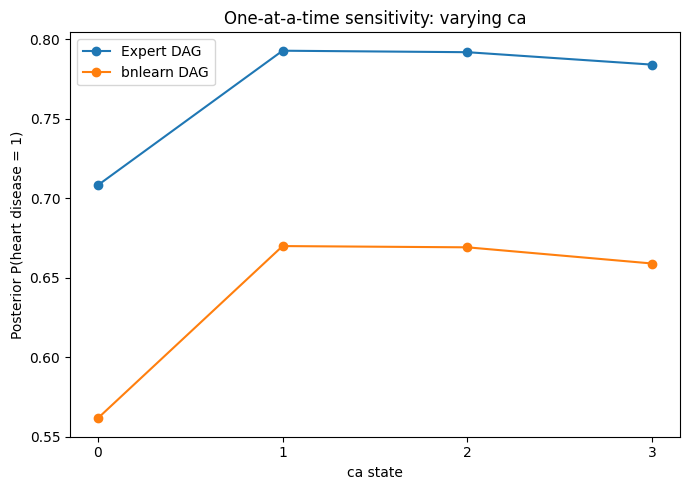

In [ ]:
base_evidence = {
    'gender': 1,
    'cp': 4,
    'exang': 1,
    'thal': 7,
    'oldpeak_cat': 'High',
    'thalach_cat': 'Low',
    'slope': 2,
}

sensitivity_rows = []
for model_name, infer_engine in [('Expert DAG', infer_expert), ('bnlearn DAG', infer_learned)]:
    for ca_state in train_bn['ca'].cat.categories:
        evidence = {**base_evidence, 'ca': ca_state}
        probability = query_prob_positive(infer_engine, evidence)
        sensitivity_rows.append({
            'Model': model_name,
            'ca': ca_state,
            'P(disease=1)': probability
        })

ca_sensitivity = pd.DataFrame(sensitivity_rows)
display(ca_sensitivity)

plt.figure(figsize=(7, 5))
for model_name, group in ca_sensitivity.groupby('Model'):
    plt.plot(group['ca'].astype(str), group['P(disease=1)'], marker='o', label=model_name)
plt.xlabel('ca state')
plt.ylabel('Posterior P(heart disease = 1)')
plt.title('One-at-a-time sensitivity: varying ca')
plt.legend()
plt.tight_layout()
plt.show()

## 16. Reverse inference — given heart disease = 1, what is the posterior distribution of important explanatory variables?

The assignment explicitly asks for variables such as `cp`, `thal`, `exang` and `ca`. The table below answers this question for **both** networks.

In [ ]:
def posterior_distribution(infer_engine, variable, evidence):
    result = infer_engine.query(
        variables=[variable],
        evidence=evidence,
        show_progress=False
    )
    return pd.DataFrame({
        'State': result.state_names[variable],
        'Probability': result.values
    })

reverse_rows = []
for model_name, infer_engine in [('Expert DAG', infer_expert), ('bnlearn DAG', infer_learned)]:
    for variable in ['cp', 'thal', 'exang', 'ca']:
        posterior = posterior_distribution(
            infer_engine,
            variable,
            evidence={TARGET: 1}
        )
        posterior.insert(0, 'Variable', variable)
        posterior.insert(0, 'Model', model_name)
        reverse_rows.append(posterior)

reverse_inference_table = pd.concat(reverse_rows, ignore_index=True)
display(reverse_inference_table)

,Model,Variable,State,Probability
0,Expert DAG,cp,1,0.214403
1,Expert DAG,cp,2,0.216039
2,Expert DAG,cp,3,0.229133
3,Expert DAG,cp,4,0.340426
4,Expert DAG,thal,3,0.321877
5,Expert DAG,thal,6,0.284233
6,Expert DAG,thal,7,0.393890
7,Expert DAG,exang,0,0.492635
8,Expert DAG,exang,1,0.507365
9,Expert DAG,ca,0,0.271964


## 17. Inference visualisations

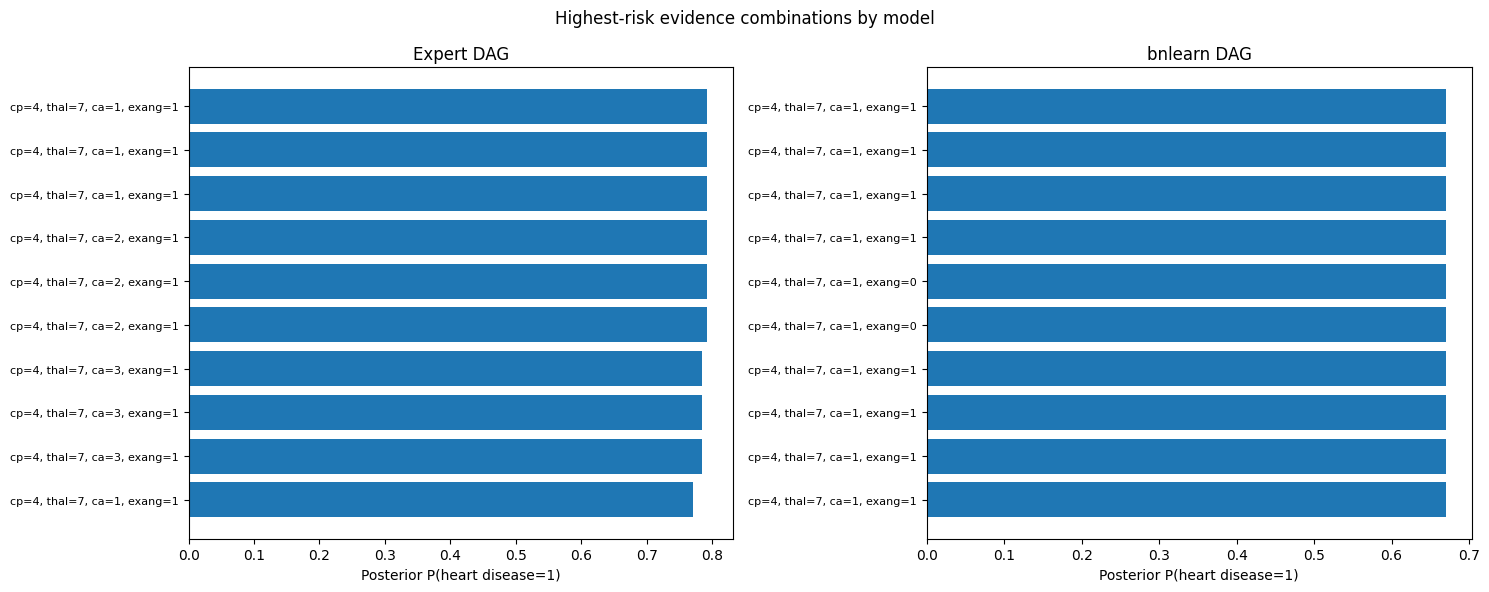

In [ ]:
# Top scenarios for both models in a single figure.
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, results, title in [
    (axes[0], expert_top, 'Expert DAG'),
    (axes[1], learned_top, 'bnlearn DAG')
]:
    plot_data = results.sort_values('Probability', ascending=True).reset_index(drop=True)
    labels = [
        f"cp={r.cp}, thal={r.thal}, ca={r.ca}, exang={r.exang}"
        for r in plot_data.itertuples()
    ]
    ax.barh(range(len(plot_data)), plot_data['Probability'])
    ax.set_yticks(range(len(plot_data)))
    ax.set_yticklabels(labels, fontsize=8)
    ax.set_xlabel('Posterior P(heart disease=1)')
    ax.set_title(title)

plt.suptitle('Highest-risk evidence combinations by model')
plt.tight_layout()
plt.show()

## 18. Held-out model evaluation

Predictions are generated row-by-row for the **test set only**. Unlike the original code, unresolved inference rows are not silently skipped: an error is raised so that both models are compared on the same held-out observations.

In [ ]:
def predict_dataframe(infer_engine, df, target=TARGET, positive_label=1):
    predictions = []
    positive_probabilities = []
    errors = []

    for idx, row in df.iterrows():
        evidence = row.drop(target).to_dict()
        try:
            result = infer_engine.query(
                variables=[target],
                evidence=evidence,
                show_progress=False
            )
            states = list(result.state_names[target])
            values = np.asarray(result.values, dtype=float)

            positive_idx = [str(s) for s in states].index(str(positive_label))
            predicted_idx = int(np.argmax(values))

            predictions.append(int(states[predicted_idx]))
            positive_probabilities.append(float(values[positive_idx]))

        except Exception as exc:
            errors.append({'Index': idx, 'Error': repr(exc)})

    if errors:
        errors_df = pd.DataFrame(errors)
        display(errors_df.head())
        raise RuntimeError(
            f'Inference failed for {len(errors)} test rows. Fix state alignment before evaluation.'
        )

    return np.asarray(predictions), np.asarray(positive_probabilities)

expert_predictions, expert_pos_probs = predict_dataframe(infer_expert, test_bn)
learned_predictions, learned_pos_probs = predict_dataframe(infer_learned, test_bn)

y_test = test_bn[TARGET].astype(int).to_numpy()

print('Resolved test rows for each model:', len(y_test))

Resolved test rows for each model: 61


### 18.1 Evaluation metrics + no-skill baseline

In [ ]:
def specificity_score(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return tn / (tn + fp) if (tn + fp) else np.nan


def summarise_classifier(y_true, preds, pos_probs, name):
    return {
        'Model': name,
        'Accuracy': accuracy_score(y_true, preds),
        'Balanced Accuracy': balanced_accuracy_score(y_true, preds),
        'Precision': precision_score(y_true, preds, zero_division=0),
        'Recall / Sensitivity': recall_score(y_true, preds, zero_division=0),
        'Specificity': specificity_score(y_true, preds),
        'F1-score': f1_score(y_true, preds, zero_division=0),
        'ROC-AUC': roc_auc_score(y_true, pos_probs),
        'PR-AUC': average_precision_score(y_true, pos_probs),
    }

# Majority-class baseline is determined from TRAIN only.
majority_class = int(train_bn[TARGET].astype(int).mode().iloc[0])
train_prevalence = float(train_bn[TARGET].astype(int).mean())
baseline_predictions = np.repeat(majority_class, len(y_test))
baseline_pos_probs = np.repeat(train_prevalence, len(y_test))

evaluation_results = pd.DataFrame([
    summarise_classifier(y_test, baseline_predictions, baseline_pos_probs, 'Majority baseline'),
    summarise_classifier(y_test, expert_predictions, expert_pos_probs, 'Expert DAG'),
    summarise_classifier(y_test, learned_predictions, learned_pos_probs, 'bnlearn DAG'),
])

display(evaluation_results.round(4))

,Model,Accuracy,Balanced Accuracy,Precision,Recall / Sensitivity,Specificity,F1-score,ROC-AUC,PR-AUC
0,Majority baseline,0.5410,0.5000,0.0000,0.0000,1.0000,0.0000,0.500,0.4590
1,Expert DAG,0.9016,0.9010,0.8929,0.8929,0.9091,0.8929,0.961,0.9532
2,bnlearn DAG,0.8525,0.8501,0.8519,0.8214,0.8788,0.8364,0.915,0.9088


### 18.2 Confusion matrices

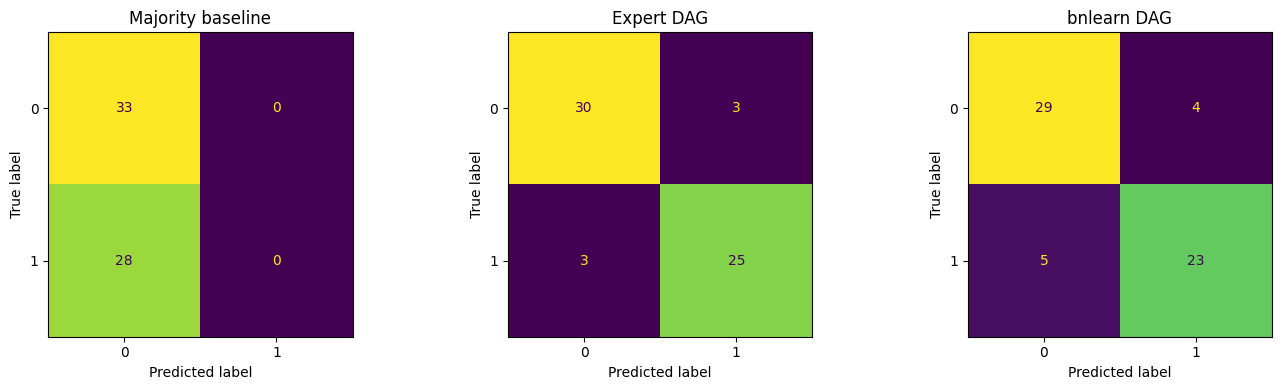

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, preds, title in [
    (axes[0], baseline_predictions, 'Majority baseline'),
    (axes[1], expert_predictions, 'Expert DAG'),
    (axes[2], learned_predictions, 'bnlearn DAG')
]:
    ConfusionMatrixDisplay(
        confusion_matrix(y_test, preds, labels=[0, 1]),
        display_labels=[0, 1]
    ).plot(ax=ax, colorbar=False)
    ax.set_title(title)

plt.tight_layout()
plt.show()

### 18.3 ROC curves

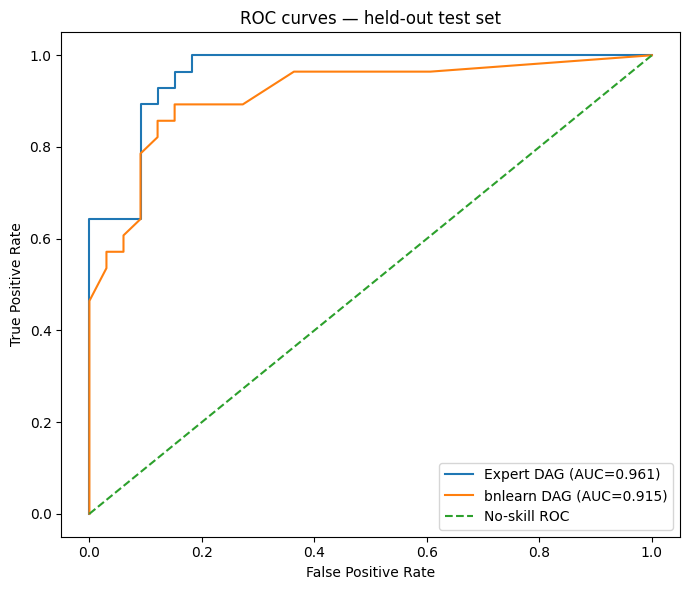

In [ ]:
plt.figure(figsize=(7, 6))

for name, probs in [
    ('Expert DAG', expert_pos_probs),
    ('bnlearn DAG', learned_pos_probs)
]:
    fpr, tpr, _ = roc_curve(y_test, probs)
    auc_value = roc_auc_score(y_test, probs)
    plt.plot(fpr, tpr, label=f'{name} (AUC={auc_value:.3f})')

plt.plot([0, 1], [0, 1], linestyle='--', label='No-skill ROC')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC curves — held-out test set')
plt.legend()
plt.tight_layout()
plt.show()

### 18.4 Precision–Recall curves

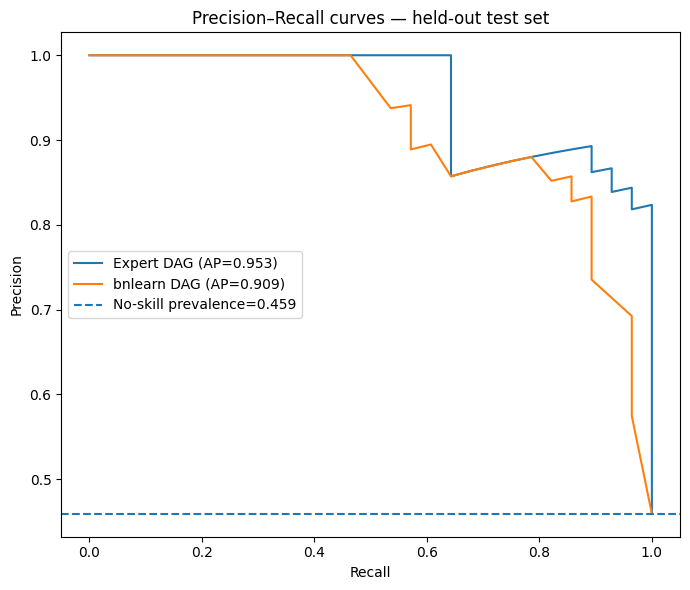

In [ ]:
plt.figure(figsize=(7, 6))

for name, probs in [
    ('Expert DAG', expert_pos_probs),
    ('bnlearn DAG', learned_pos_probs)
]:
    precision, recall, _ = precision_recall_curve(y_test, probs)
    ap = average_precision_score(y_test, probs)
    plt.plot(recall, precision, label=f'{name} (AP={ap:.3f})')

plt.axhline(y_test.mean(), linestyle='--', label=f'No-skill prevalence={y_test.mean():.3f}')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision–Recall curves — held-out test set')
plt.legend()
plt.tight_layout()
plt.show()

## 19. Evidence-based model comparison and reflection

The final code cell summarises predictive performance and structural complexity. The narrative report should then answer two separate questions:

1. **Which DAG predicts heart disease better on unseen observations?**
2. **Which DAG is easier to explain and defend?**

A higher predictive score does not automatically make a learned DAG more causal or more clinically interpretable.

In [ ]:
model_rows = evaluation_results[evaluation_results['Model'].isin(['Expert DAG', 'bnlearn DAG'])]
best_by_f1 = model_rows.loc[model_rows['F1-score'].idxmax(), 'Model']
best_by_auc = model_rows.loc[model_rows['ROC-AUC'].idxmax(), 'Model']

complexity_table = pd.DataFrame([
    {
        'Model': 'Expert DAG',
        'Edges': len(DAG_expert['model_edges']),
        'Direct target parents': len(list(model_expert['model'].predecessors(TARGET)))
    },
    {
        'Model': 'bnlearn DAG',
        'Edges': len(DAG_learned['model_edges']),
        'Direct target parents': len(list(model_learned['model'].predecessors(TARGET)))
    }
])

print('Best model by held-out F1-score:', best_by_f1)
print('Best model by held-out ROC-AUC:', best_by_auc)
print('\nPredictive evaluation:')
display(evaluation_results.round(4))
print('\nStructural complexity:')
display(complexity_table)

expert_f1 = float(model_rows.loc[model_rows['Model'] == 'Expert DAG', 'F1-score'].iloc[0])
learned_f1 = float(model_rows.loc[model_rows['Model'] == 'bnlearn DAG', 'F1-score'].iloc[0])

if learned_f1 > expert_f1:
    print(
        '\nReflection: The bnlearn DAG has the stronger held-out F1-score in this run. '
        'The expert DAG remains valuable for transparent, domain-informed diagnostic pathways. '
        'The final report should therefore distinguish predictive performance from interpretability rather than treating them as the same criterion.'
    )
elif expert_f1 > learned_f1:
    print(
        '\nReflection: The expert DAG has the stronger held-out F1-score in this run and also offers explicit domain-informed pathways. '
        'The final report should still discuss any learned-DAG relationships that provide useful alternative structure.'
    )
else:
    print(
        '\nReflection: The models tie on held-out F1-score in this run. Interpretability, calibration, ROC/PR performance and structural plausibility become important tie-breakers.'
    )

Best model by held-out F1-score: Expert DAG
Best model by held-out ROC-AUC: Expert DAG

Predictive evaluation:


,Model,Accuracy,Balanced Accuracy,Precision,Recall / Sensitivity,Specificity,F1-score,ROC-AUC,PR-AUC
0,Majority baseline,0.5410,0.5000,0.0000,0.0000,1.0000,0.0000,0.500,0.4590
1,Expert DAG,0.9016,0.9010,0.8929,0.8929,0.9091,0.8929,0.961,0.9532
2,bnlearn DAG,0.8525,0.8501,0.8519,0.8214,0.8788,0.8364,0.915,0.9088



Structural complexity:


,Model,Edges,Direct target parents
0,Expert DAG,16,4
1,bnlearn DAG,11,1



Reflection: The expert DAG has the stronger held-out F1-score in this run and also offers explicit domain-informed pathways. The final report should still discuss any learned-DAG relationships that provide useful alternative structure.
